<a href="https://colab.research.google.com/github/biswal-prem-5677/10xCoders-Platform/blob/main/ai/03_deep_learning/architectures/cnn/experiment_cnn_image_embedding_resnet18_retrieval_comparison_cifar100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Custom Image Embedding Model: Improved, Validated and Compared

This notebook trains a CNN **from scratch** on CIFAR-100 that turns an image into a 256-number vector (an embedding) for FAISS image search.

It shows, step by step, with plots **and** numbers:

1. The data and how it is split (train / validation / test)
2. Two models: your **original CNN** and an **improved ResNet-18** (both from scratch)
3. Training curves, so you can see learning and overfitting
4. Final test accuracy (the test set is used **once**)
5. Where the model fails (per-class accuracy, common mistakes)
6. Image-search quality (Recall@K, Precision@K, mAP@10) with example searches
7. The embedding space (t-SNE + a clustering score)
8. Comparison with existing models (ResNet-50, DINOv2, CLIP)
9. Saving the model for your project

**Before running:** Runtime → Change runtime type → GPU. Then **Restart and run all** so no old trained weights are reused. Total time is about 40 minutes at the default settings; the optional seed check at the end adds about 20 more.

## 1. Setup

In [ ]:
!pip -q install faiss-cpu

In [ ]:
import time, copy, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# ---- settings you may want to change ----
SEED = 42
EPOCHS = 30          # use 2 for a quick test run
BATCH_SIZE = 128
LR = 2e-3
EMB_DIM = 256        # size of the embedding vector

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"       # mixed precision: faster on GPU
print("Using device:", DEVICE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

Using device: cuda


## 2. Data and the train / validation / test split

* **Train (45,000 images):** the model learns from these.
* **Validation (5,000 images):** used during training to pick the best epoch and spot overfitting. The model never learns from these.
* **Test (10,000 images, official CIFAR-100 test set):** used **once at the end** for the final numbers. It is never used to make any decision.

This is what makes the final numbers trustworthy. Images stay at their original 32×32 size (no upsampling).

In [ ]:
MEAN, STD = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)     # CIFAR-100 channel statistics

# training images get random crop + flip (augmentation); validation/test images are left untouched
train_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_aug   = datasets.CIFAR100("./data", train=True,  download=True, transform=train_tf)
train_plain = datasets.CIFAR100("./data", train=True,  download=True, transform=plain_tf)   # same images, no augmentation
test_set    = datasets.CIFAR100("./data", train=False, download=True, transform=plain_tf)
class_names = train_aug.classes

train_labels_np = np.array(train_aug.targets); test_labels_np = np.array(test_set.targets)

# split the 50,000 training images into 45,000 train + 5,000 validation
perm = np.random.RandomState(SEED).permutation(50000)
train_idx, val_idx = perm[:45000], perm[45000:]
assert len(set(train_idx) & set(val_idx)) == 0, "train and validation overlap!"

train_loader = DataLoader(Subset(train_aug, train_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(Subset(train_plain, val_idx), batch_size=500, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=500, shuffle=False, num_workers=2)

print(f"train: {len(train_idx)} | validation: {len(val_idx)} | test: {len(test_set)} | classes: {len(class_names)}")
print("train/validation overlap: 0 images (checked)")
print(f"images per class in train: min {np.bincount(train_labels_np[train_idx]).min()}, max {np.bincount(train_labels_np[train_idx]).max()}")
print(f"images per class in validation: min {np.bincount(train_labels_np[val_idx]).min()}, max {np.bincount(train_labels_np[val_idx]).max()}")

100%|██████████| 169M/169M [00:06<00:00, 26.7MB/s]


train: 45000 | validation: 5000 | test: 10000 | classes: 100
train/validation overlap: 0 images (checked)
images per class in train: min 426, max 468
images per class in validation: min 32, max 74


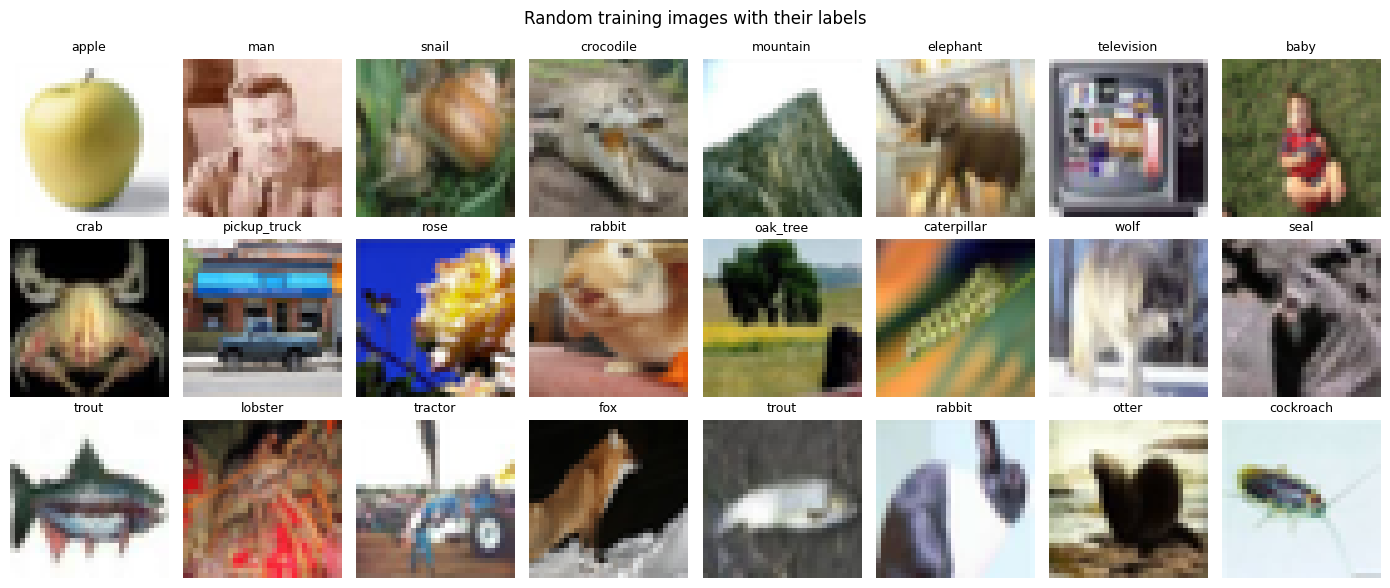

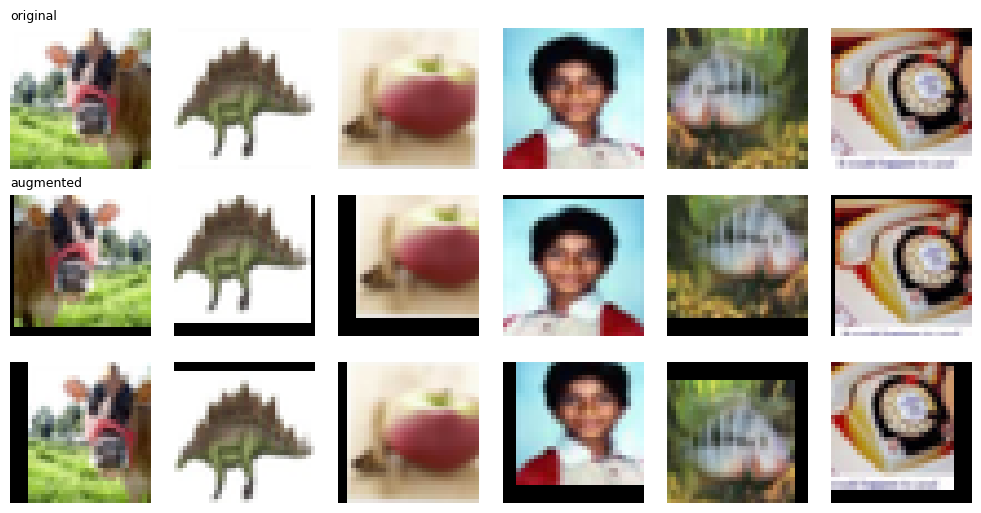

In [ ]:
# What the data looks like
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(50000, 24, replace=False)):
    ax.imshow(train_aug.data[i]); ax.set_title(class_names[train_labels_np[i]], fontsize=9); ax.axis("off")
plt.suptitle("Random training images with their labels"); plt.tight_layout(); plt.show()

# What augmentation does (the model sees a slightly different version every epoch)
aug_only = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()])
fig, axes = plt.subplots(3, 6, figsize=(10, 5.2))
for col, i in enumerate(range(6)):
    img = Image.fromarray(train_aug.data[i])
    axes[0, col].imshow(img); axes[1, col].imshow(aug_only(img)); axes[2, col].imshow(aug_only(img))
for a in axes.flat: a.axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=9); axes[1, 0].set_title("augmented", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 3. The two models

**Original CNN (your first model):** 4 convolution blocks, then flatten, then a linear layer with ReLU.

**Improved ResNet-18:** same idea, with three changes that matter:
* **Skip connections (residual blocks)** let the network be much deeper and still train well.
* **Global average pooling** instead of flatten, which removes a huge, easily-overfitting linear layer.
* **No ReLU on the embedding** (a BatchNorm instead), so vectors can use the full range and compare better with cosine similarity.

Both models return `(logits, embedding)` exactly like your project's `EmbeddingCNN`, so they plug in the same way. Both are trained from random weights.

In [ ]:
class OriginalCNN(nn.Module):
    def __init__(self, emb_dim=EMB_DIM, num_classes=100):
        super().__init__()
        def block(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 64), *block(64, 128), *block(128, 256), *block(256, 256))
        self.embedding_layer = nn.Sequential(nn.Flatten(), nn.Linear(256 * 2 * 2, emb_dim), nn.ReLU())
        self.classifier = nn.Linear(emb_dim, num_classes)

    def forward(self, x, return_embedding=False):
        emb = self.embedding_layer(self.features(x))
        if return_embedding:
            return emb
        return self.classifier(emb), emb


class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        if stride == 1 and cin == cout:
            self.skip = nn.Identity()
        else:
            self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.skip(x))          # skip connection: add the input back


class EmbeddingResNet(nn.Module):
    def __init__(self, emb_dim=EMB_DIM, num_classes=100):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
        self.blocks = nn.Sequential(
            ResBlock(64, 64, 1),   ResBlock(64, 64, 1),
            ResBlock(64, 128, 2),  ResBlock(128, 128, 1),
            ResBlock(128, 256, 2), ResBlock(256, 256, 1),
            ResBlock(256, 512, 2), ResBlock(512, 512, 1))
        self.embedding_layer = nn.Sequential(nn.Linear(512, emb_dim), nn.BatchNorm1d(emb_dim))
        self.classifier = nn.Linear(emb_dim, num_classes)

    def forward(self, x, return_embedding=False):
        x = self.blocks(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)       # global average pooling
        emb = self.embedding_layer(x)
        if return_embedding:
            return emb
        return self.classifier(emb), emb


for cls in (OriginalCNN, EmbeddingResNet):
    print(f"{cls.__name__:<16} parameters: {sum(p.numel() for p in cls().parameters()):,}")

OriginalCNN      parameters: 1,250,404
EmbeddingResNet  parameters: 11,326,372


## 4. Training

Both models use **exactly the same** data, augmentation, optimizer, schedule and number of epochs, so any difference in the results comes from the model itself.

After every epoch we print the training loss, training accuracy and **validation accuracy**. The best epoch (by validation accuracy) is kept.

In [ ]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); all_logits, all_labels = [], []
    for images, labels in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits, _ = model(images.to(DEVICE))
        all_logits.append(logits.float().cpu()); all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)

def accuracy(model, loader):
    logits, labels = predict(model, loader)
    return (logits.argmax(1) == labels).float().mean().item()


def train_model(model_class, name, seed=SEED, epochs=EPOCHS):
    set_seed(seed)
    model = model_class().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=epochs, steps_per_epoch=len(train_loader))
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {"train_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_epoch, best_state = 0.0, 0, None
    start = time.time()
    print(f"=== {name} ===")
    for epoch in range(1, epochs + 1):
        model.train(); loss_sum, correct, total = 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f"epoch {epoch}/{epochs}", leave=False):
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits, _ = model(images)
                loss = criterion(logits, labels)
            optimizer.zero_grad()
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * len(labels); correct += (logits.argmax(1) == labels).sum().item(); total += len(labels)

        history["train_loss"].append(loss_sum / total)
        history["train_acc"].append(correct / total)
        history["val_acc"].append(accuracy(model, val_loader))
        if history["val_acc"][-1] > best_val:
            best_val, best_epoch, best_state = history["val_acc"][-1], epoch, copy.deepcopy(model.state_dict())
        print(f"epoch {epoch:2d} | loss {history['train_loss'][-1]:.3f} | train acc {history['train_acc'][-1]:.3f} | val acc {history['val_acc'][-1]:.3f}")

    model.load_state_dict(best_state)                      # go back to the best epoch
    history.update(best_val=best_val, best_epoch=best_epoch, minutes=(time.time() - start) / 60)
    print(f"best epoch: {best_epoch} (validation accuracy {best_val:.4f}) | time: {history['minutes']:.1f} min\n")
    return model, history

In [ ]:
cnn_model, cnn_hist = train_model(OriginalCNN, "Original CNN")

=== Original CNN ===


epoch 1/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  1 | loss 4.048 | train acc 0.117 | val acc 0.190


epoch 2/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  2 | loss 3.415 | train acc 0.239 | val acc 0.272


epoch 3/30:   0%|          | 0/352 [00:00<?, ?it/s]

... (51 outputs left out)

epoch 29/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 29 | loss 1.324 | train acc 0.878 | val acc 0.640


epoch 30/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 30 | loss 1.321 | train acc 0.880 | val acc 0.642
best epoch: 30 (validation accuracy 0.6422) | time: 11.1 min



In [ ]:
res_model, res_hist = train_model(EmbeddingResNet, "Improved ResNet-18")

=== Improved ResNet-18 ===


epoch 1/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  1 | loss 3.918 | train acc 0.136 | val acc 0.197


epoch 2/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  2 | loss 3.344 | train acc 0.248 | val acc 0.258


epoch 3/30:   0%|          | 0/352 [00:00<?, ?it/s]

... (51 outputs left out)

epoch 29/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 29 | loss 0.884 | train acc 0.995 | val acc 0.730


epoch 30/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 30 | loss 0.880 | train acc 0.996 | val acc 0.729
best epoch: 28 (validation accuracy 0.7304) | time: 11.2 min



### Training curves
* **Loss going down and accuracy going up** means the model is learning.
* A **big gap between train accuracy and validation accuracy** means overfitting (memorising instead of learning).
* The dashed line marks the epoch we kept, chosen on validation data only.

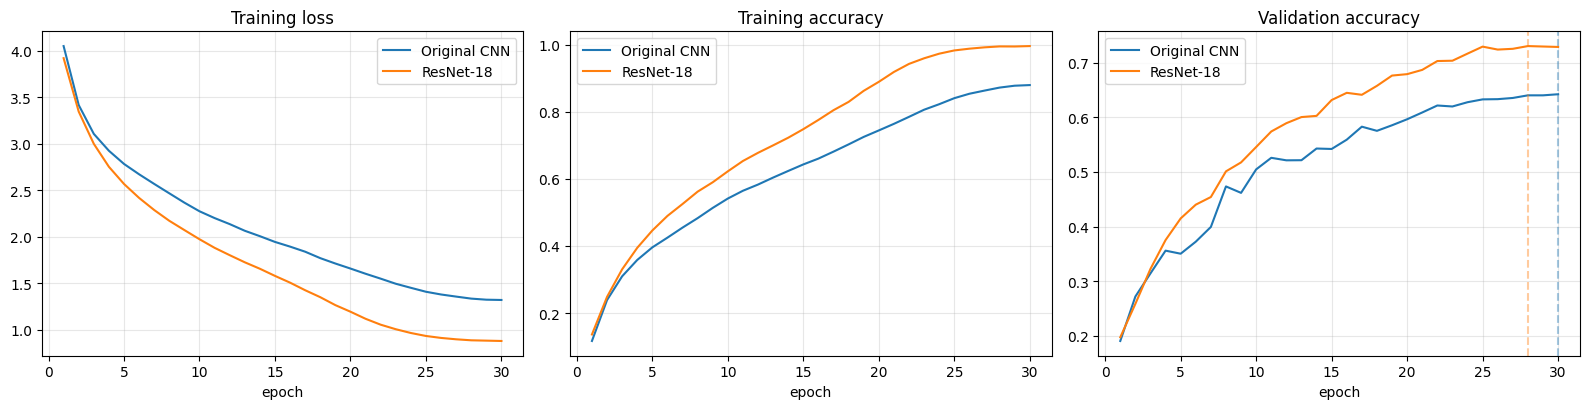

,best epoch,train acc %,validation acc %,gap (train - val) %,minutes
model,,,,,
Original CNN,30,88.0,64.2,23.7,11.1
ResNet-18,28,99.5,73.0,26.5,11.2


In [ ]:
histories = {"Original CNN": cnn_hist, "ResNet-18": res_hist}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name, h in histories.items():
    epochs_x = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(epochs_x, h["train_loss"], label=name)
    axes[1].plot(epochs_x, h["train_acc"], label=name)
    axes[2].plot(epochs_x, h["val_acc"], label=name)
    axes[2].axvline(h["best_epoch"], ls="--", alpha=0.4, color=axes[2].lines[-1].get_color())
for ax, title in zip(axes, ["Training loss", "Training accuracy", "Validation accuracy"]):
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

rows = []
for name, h in histories.items():
    i = h["best_epoch"] - 1
    rows.append({"model": name, "best epoch": h["best_epoch"], "train acc %": h["train_acc"][i] * 100,
                 "validation acc %": h["val_acc"][i] * 100, "gap (train - val) %": (h["train_acc"][i] - h["val_acc"][i]) * 100,
                 "minutes": h["minutes"]})
display(pd.DataFrame(rows).set_index("model").round(1))

## 5. Final test results (test set used once)

* **Top-1 accuracy:** the model's single best guess is correct.
* **Top-5 accuracy:** the correct class is among the model's 5 best guesses.

Original CNN   test top-1: 65.43% | test top-5: 88.23%
ResNet-18      test top-1: 73.44% | test top-5: 91.58%

Improvement in top-1 accuracy: +8.01 percentage points


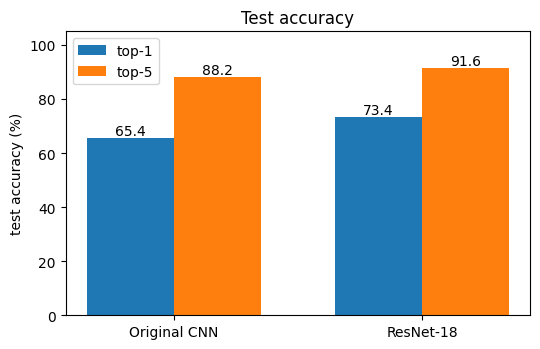

In [ ]:
test_results = {}
for name, model in [("Original CNN", cnn_model), ("ResNet-18", res_model)]:
    logits, labels = predict(model, test_loader)
    top1 = (logits.argmax(1) == labels).float().mean().item()
    top5 = (logits.topk(5, dim=1).indices == labels[:, None]).any(1).float().mean().item()
    test_results[name] = {"top1": top1, "top5": top5}
    print(f"{name:<14} test top-1: {top1*100:.2f}% | test top-5: {top5*100:.2f}%")

gain = (test_results["ResNet-18"]["top1"] - test_results["Original CNN"]["top1"]) * 100
print(f"\nImprovement in top-1 accuracy: {gain:+.2f} percentage points")

plt.figure(figsize=(5.5, 3.6))
x = np.arange(2); w = 0.35
b1 = plt.bar(x - w/2, [test_results[n]["top1"]*100 for n in test_results], w, label="top-1")
b2 = plt.bar(x + w/2, [test_results[n]["top5"]*100 for n in test_results], w, label="top-5")
plt.bar_label(b1, fmt="%.1f"); plt.bar_label(b2, fmt="%.1f")
plt.xticks(x, list(test_results)); plt.ylabel("test accuracy (%)"); plt.ylim(0, 105); plt.legend(); plt.title("Test accuracy"); plt.tight_layout(); plt.show()

## 6. Where does the improved model fail?

Per-class accuracy and the most common mistakes show whether the errors make sense (for example confusing similar-looking classes) or point to something wrong.

5 hardest classes: [('bear', '43%'), ('seal', '48%'), ('otter', '50%'), ('man', '52%'), ('possum', '52%')]
5 easiest classes: [('road', '94%'), ('motorcycle', '94%'), ('orange', '93%'), ('sunflower', '93%'), ('skunk', '92%')]
Spread across classes: min 43%, median 75%, max 94%


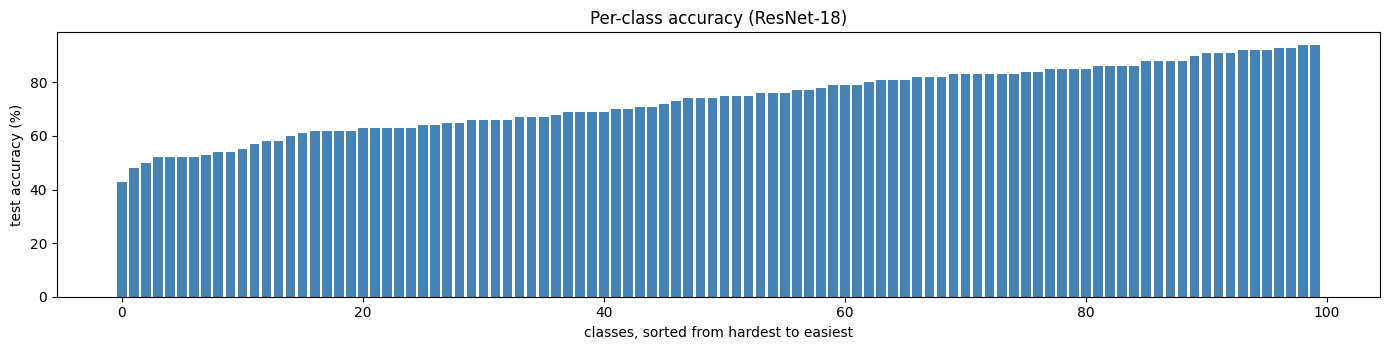


Most common mistakes (true class -> predicted class, number of test images):
  woman          -> girl           20
  oak_tree       -> maple_tree     16
  boy            -> girl           15
  baby           -> boy            15
  plate          -> bowl           15
  maple_tree     -> oak_tree       14
  willow_tree    -> maple_tree     14
  man            -> woman          13
  oak_tree       -> pine_tree      13
  mouse          -> shrew          13


In [ ]:
logits, labels = predict(res_model, test_loader)
preds = logits.argmax(1)
per_class = np.array([(preds[labels == c] == c).float().mean().item() for c in range(100)])
order = np.argsort(per_class)

print("5 hardest classes:", [(class_names[c], f"{per_class[c]*100:.0f}%") for c in order[:5]])
print("5 easiest classes:", [(class_names[c], f"{per_class[c]*100:.0f}%") for c in order[::-1][:5]])
print(f"Spread across classes: min {per_class.min()*100:.0f}%, median {np.median(per_class)*100:.0f}%, max {per_class.max()*100:.0f}%")

plt.figure(figsize=(14, 3.6))
plt.bar(range(100), per_class[order] * 100, color="steelblue")
plt.xlabel("classes, sorted from hardest to easiest"); plt.ylabel("test accuracy (%)"); plt.title("Per-class accuracy (ResNet-18)")
plt.tight_layout(); plt.show()

print("\nMost common mistakes (true class -> predicted class, number of test images):")
mistakes = Counter((class_names[t], class_names[p]) for t, p in zip(labels.tolist(), preds.tolist()) if t != p)
for (t, p), n in mistakes.most_common(10):
    print(f"  {t:<14} -> {p:<14} {n}")

## 7. Image search quality (what your project actually uses)

In the project, a query image is turned into a vector and the most similar stored images are returned. We measure this honestly:

* **Queries:** the 10,000 test images. **Gallery:** the 50,000 training images. A query is never in the gallery.
* A result is **correct** if it has the same class as the query.
* **Recall@K:** is at least one of the top-K results correct?
* **Precision@10:** what fraction of the top-10 results are correct?
* **mAP@10:** like precision, but rewards putting correct results at the very top. Higher is better.

Vectors are length-normalised, so the dot product equals cosine similarity.

In [ ]:
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

@torch.no_grad()
def extract_embeddings(forward_fn, images_uint8, mean, std, size=None, batch_size=500):
    # images_uint8: numpy array (N, 32, 32, 3). Returns L2-normalised embeddings on the GPU.
    mean_t = torch.tensor(mean, device=DEVICE).view(1, 3, 1, 1); std_t = torch.tensor(std, device=DEVICE).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(images_uint8), batch_size):
        x = torch.from_numpy(images_uint8[i:i + batch_size]).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
        if size: x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
        x = (x - mean_t) / std_t
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            e = forward_fn(x)
        out.append(F.normalize(e.float(), dim=1))
    return torch.cat(out)

gallery_labels = torch.tensor(train_labels_np, device=DEVICE)     # 50,000 gallery images
query_labels   = torch.tensor(test_labels_np, device=DEVICE)      # 10,000 query images

@torch.no_grad()
def retrieval_scores(query_emb, gallery_emb, k=10):
    hits = []
    for i in range(0, len(query_emb), 1000):
        top = (query_emb[i:i + 1000] @ gallery_emb.T).topk(k, dim=1).indices
        hits.append((gallery_labels[top] == query_labels[i:i + 1000, None]).float())
    hits = torch.cat(hits)                                   # (num_queries, k), 1 = correct class
    precision_at = hits.cumsum(1) / torch.arange(1, k + 1, device=hits.device)
    return {"Recall@1": hits[:, :1].max(1).values.mean().item(),
            "Recall@5": hits[:, :5].max(1).values.mean().item(),
            "Recall@10": hits.max(1).values.mean().item(),
            "Precision@10": hits.mean().item(),
            "mAP@10": (precision_at * hits).sum(1).div(k).mean().item()}

cnn_model.eval(); res_model.eval()
embeddings, search_scores = {}, {}
for name, model in [("Original CNN", cnn_model), ("ResNet-18", res_model)]:
    fn = lambda x, m=model: m(x, return_embedding=True)
    g = extract_embeddings(fn, train_aug.data, MEAN, STD); q = extract_embeddings(fn, test_set.data, MEAN, STD)
    embeddings[name] = (q, g)
    search_scores[name] = retrieval_scores(q, g)

display((pd.DataFrame(search_scores).T * 100).round(2))

,Recall@1,Recall@5,Recall@10,Precision@10,mAP@10
Original CNN,59.93,78.80,84.89,52.93,45.71
ResNet-18,72.91,81.42,84.54,71.67,68.38


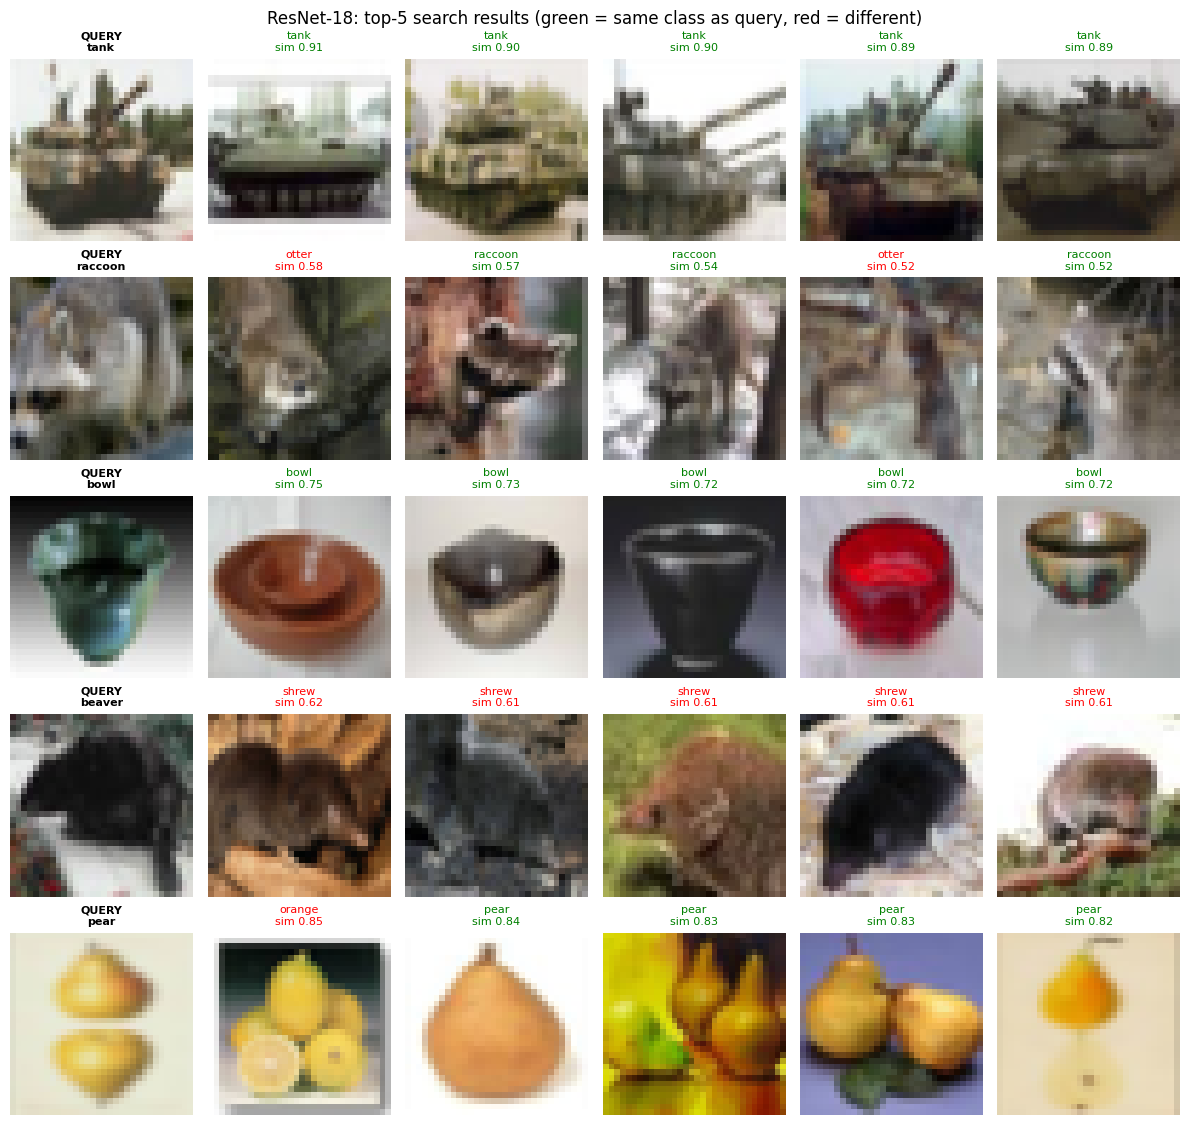

In [ ]:
def show_search_examples(name, n=5, k=5, seed=3):
    q_emb, g_emb = embeddings[name]
    ids = np.random.RandomState(seed).choice(len(q_emb), n, replace=False)
    fig, axes = plt.subplots(n, k + 1, figsize=(2 * (k + 1), 2.3 * n))
    for r, qi in enumerate(ids):
        scores, top = (q_emb[qi] @ g_emb.T).topk(k)
        axes[r, 0].imshow(test_set.data[qi]); axes[r, 0].set_title("QUERY\n" + class_names[test_labels_np[qi]], fontsize=8, fontweight="bold")
        for c, (s, gi) in enumerate(zip(scores.tolist(), top.tolist())):
            correct = train_labels_np[gi] == test_labels_np[qi]
            axes[r, c + 1].imshow(train_aug.data[gi])
            axes[r, c + 1].set_title(f"{class_names[train_labels_np[gi]]}\nsim {s:.2f}", fontsize=8, color="green" if correct else "red")
    for a in axes.flat: a.axis("off")
    plt.suptitle(f"{name}: top-{k} search results (green = same class as query, red = different)"); plt.tight_layout(); plt.show()

show_search_examples("ResNet-18")

In [ ]:
# Your project uses FAISS, so check that FAISS gives the same answers as our evaluation code
import faiss
g_np = embeddings["ResNet-18"][1].cpu().numpy().astype("float32")
q_np = embeddings["ResNet-18"][0][:1000].cpu().numpy().astype("float32")
index = faiss.IndexFlatIP(g_np.shape[1]); index.add(g_np)
_, faiss_ids = index.search(q_np, 1)
torch_ids = (embeddings["ResNet-18"][0][:1000] @ embeddings["ResNet-18"][1].T).argmax(1).cpu().numpy()
print(f"FAISS top-1 result matches our evaluation code for {(faiss_ids[:, 0] == torch_ids).mean()*100:.1f}% of 1000 queries")

FAISS top-1 result matches our evaluation code for 100.0% of 1000 queries


## 8. The embedding space

If the vectors are good, images of the same class should sit close together. We plot 10 random classes (100 test images each) in 2-D with t-SNE, and also compute a **silhouette score** (cosine): it ranges from -1 to 1, and higher means tighter, better-separated clusters.

Original CNN: silhouette score = 0.160
ResNet-18: silhouette score = 0.293


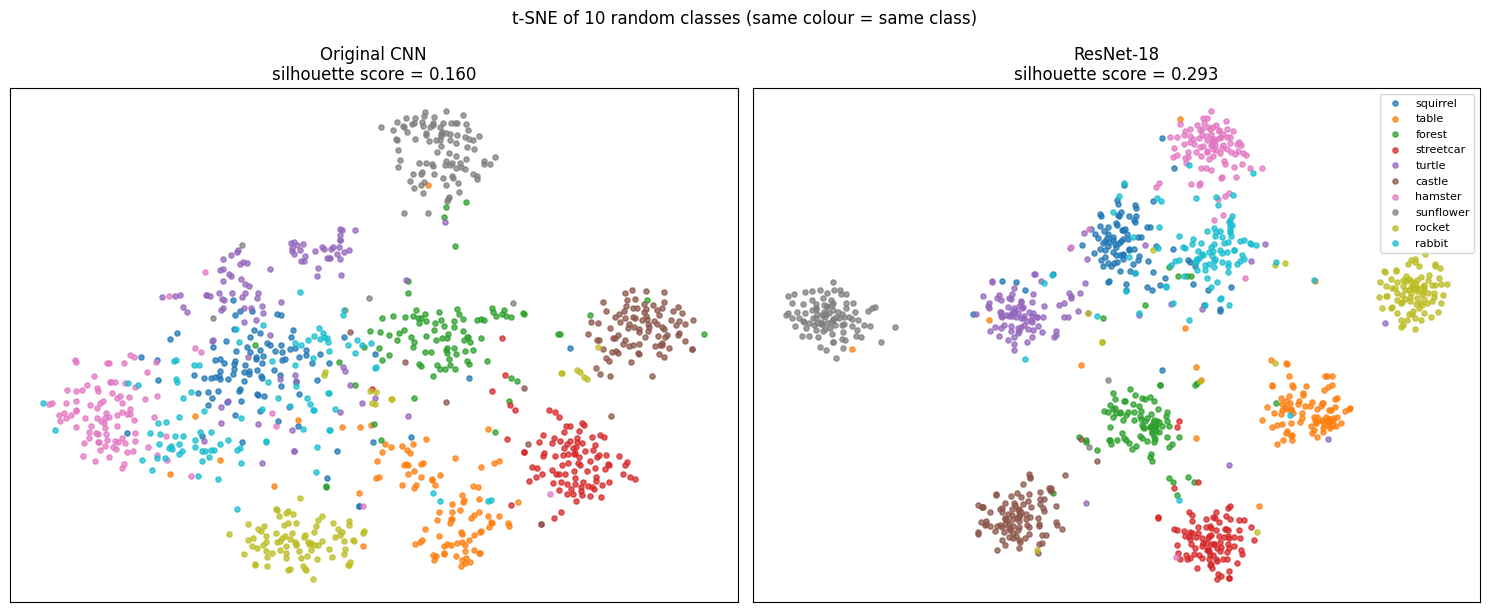

In [ ]:
classes_to_show = np.random.RandomState(1).choice(100, 10, replace=False)
sel = np.concatenate([np.where(test_labels_np == c)[0][:100] for c in classes_to_show])
sel_labels = test_labels_np[sel]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
cmap = plt.get_cmap("tab10")
for ax, name in zip(axes, ["Original CNN", "ResNet-18"]):
    emb = embeddings[name][0][sel].cpu().numpy()
    sil = silhouette_score(emb, sel_labels, metric="cosine")
    xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(emb)
    for k, c in enumerate(classes_to_show):
        m = sel_labels == c
        ax.scatter(xy[m, 0], xy[m, 1], s=14, alpha=0.75, color=cmap(k), label=class_names[c])
    ax.set_title(f"{name}\nsilhouette score = {sil:.3f}"); ax.set_xticks([]); ax.set_yticks([])
    print(f"{name}: silhouette score = {sil:.3f}")
axes[1].legend(fontsize=8, loc="best")
plt.suptitle("t-SNE of 10 random classes (same colour = same class)"); plt.tight_layout(); plt.show()

## 9. Comparison with existing models

These are well-known models used **frozen** (no training on CIFAR-100), producing one vector per image with the same search test as above:

* **ResNet-50** trained on ImageNet (1.3M images)
* **DINOv2 ViT-S/14** trained on a large curated image set (self-supervised)
* **CLIP ViT-B/32** trained on 400M image-text pairs (the model your project originally used)

Our model learns from scratch on only 45,000 small images, so the large pretrained models are *expected* to win. The point of the comparison is to show where your model stands, and the size and training-data gap that explains it. CIFAR images are enlarged to 224×224 for these models. If a download fails, that model is skipped and the rest still run.

In [ ]:
CLIP_MEAN, CLIP_STD = (0.4815, 0.4578, 0.4082), (0.2686, 0.2613, 0.2758)
scores_table, info_table = {}, {}
for name in ["Original CNN", "ResNet-18"]:
    scores_table[name] = search_scores[name]
    info_table[name] = (EMB_DIM, "CIFAR-100, from scratch (45k images)")

def add_existing(name, forward_fn, mean, std, trained_on):
    start = time.time()
    g = extract_embeddings(forward_fn, train_aug.data, mean, std, size=224)
    q = extract_embeddings(forward_fn, test_set.data, mean, std, size=224)
    scores_table[name] = retrieval_scores(q, g)
    info_table[name] = (g.shape[1], trained_on)
    print(f"{name}: done in {(time.time() - start) / 60:.1f} min | Recall@1 = {scores_table[name]['Recall@1']*100:.1f}%")
    del g, q; torch.cuda.empty_cache()

try:
    r50 = models.resnet50(weights="IMAGENET1K_V2"); r50.fc = nn.Identity(); r50 = r50.to(DEVICE).eval()
    add_existing("ResNet-50 (frozen)", r50, IMNET_MEAN, IMNET_STD, "ImageNet (1.3M images)")
    del r50
except Exception as e:
    print("ResNet-50 skipped:", e)

try:
    dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(DEVICE).eval()
    add_existing("DINOv2 ViT-S/14 (frozen)", dino, IMNET_MEAN, IMNET_STD, "LVD-142M images (self-supervised)")
    del dino
except Exception as e:
    print("DINOv2 skipped:", e)

try:
    from transformers import CLIPModel
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
    def clip_forward(x):
        out = clip.get_image_features(pixel_values=x)
        return out if torch.is_tensor(out) else out.pooler_output
    add_existing("CLIP ViT-B/32 (frozen)", clip_forward, CLIP_MEAN, CLIP_STD, "400M image-text pairs")
    del clip
except Exception as e:
    print("CLIP skipped:", e)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 160MB/s]


ResNet-50 (frozen): done in 1.3 min | Recall@1 = 62.7%
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 226MB/s]


... (4 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP ViT-B/32 (frozen): done in 0.8 min | Recall@1 = 65.2%


,Recall@1,Recall@5,Recall@10,Precision@10,mAP@10,vector size,trained on
Original CNN,59.9,78.8,84.9,52.9,45.7,256,"CIFAR-100, from scratch (45k images)"
ResNet-18,72.9,81.4,84.5,71.7,68.4,256,"CIFAR-100, from scratch (45k images)"
ResNet-50 (frozen),62.7,82.8,88.7,52.0,44.2,2048,ImageNet (1.3M images)
DINOv2 ViT-S/14 (frozen),76.4,90.7,94.2,69.0,63.1,384,LVD-142M images (self-supervised)
CLIP ViT-B/32 (frozen),65.2,84.4,90.2,56.2,48.6,512,400M image-text pairs


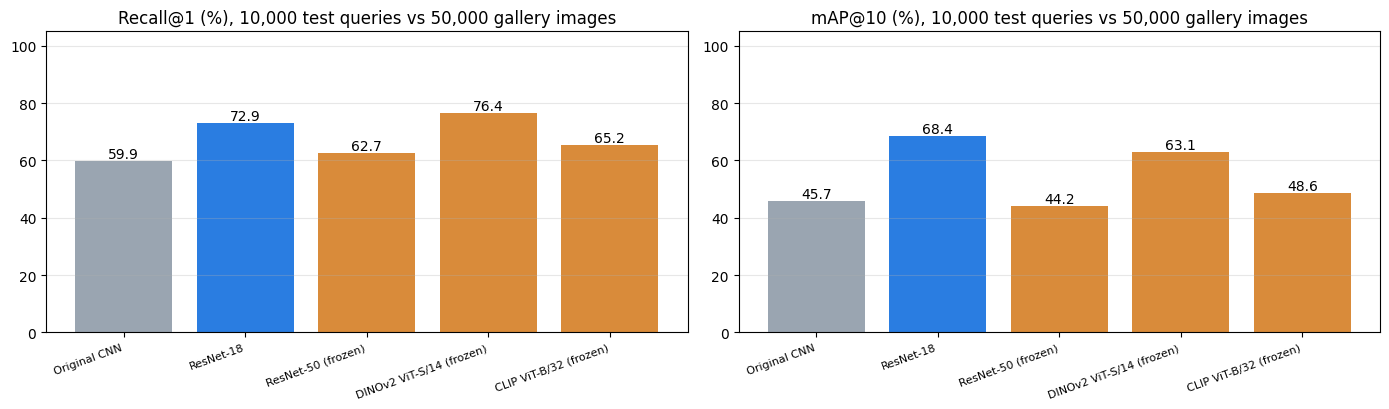

In [ ]:
comparison = (pd.DataFrame(scores_table).T * 100).round(1)
comparison["vector size"] = [info_table[n][0] for n in comparison.index]
comparison["trained on"] = [info_table[n][1] for n in comparison.index]
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
names = list(comparison.index)
colors = ["#9aa5b1" if n == "Original CNN" else "#2a7de1" if n == "ResNet-18" else "#d98b3a" for n in names]
for ax, metric in zip(axes, ["Recall@1", "mAP@10"]):
    bars = ax.bar(range(len(names)), comparison[metric], color=colors)
    ax.bar_label(bars, fmt="%.1f"); ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{metric} (%), 10,000 test queries vs 50,000 gallery images"); ax.set_ylim(0, 105); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Summary

In [ ]:
o, r = search_scores["Original CNN"], search_scores["ResNet-18"]
print("ORIGINAL CNN  ->  IMPROVED RESNET-18   (all numbers on the untouched test set)")
print(f"  Top-1 accuracy : {test_results['Original CNN']['top1']*100:5.1f}%  ->  {test_results['ResNet-18']['top1']*100:5.1f}%")
print(f"  Top-5 accuracy : {test_results['Original CNN']['top5']*100:5.1f}%  ->  {test_results['ResNet-18']['top5']*100:5.1f}%")
print(f"  Search Recall@1: {o['Recall@1']*100:5.1f}%  ->  {r['Recall@1']*100:5.1f}%")
print(f"  Search mAP@10  : {o['mAP@10']*100:5.1f}%  ->  {r['mAP@10']*100:5.1f}%")
print(f"  Overfitting gap (train - val accuracy): {(cnn_hist['train_acc'][cnn_hist['best_epoch']-1]-cnn_hist['val_acc'][cnn_hist['best_epoch']-1])*100:.1f}  ->  "
      f"{(res_hist['train_acc'][res_hist['best_epoch']-1]-res_hist['val_acc'][res_hist['best_epoch']-1])*100:.1f} points")

ORIGINAL CNN  ->  IMPROVED RESNET-18   (all numbers on the untouched test set)
  Top-1 accuracy :  65.4%  ->   73.4%
  Top-5 accuracy :  88.2%  ->   91.6%
  Search Recall@1:  59.9%  ->   72.9%
  Search mAP@10  :  45.7%  ->   68.4%
  Overfitting gap (train - val accuracy): 23.7  ->  26.5 points


## 11. Save the model for your project

The checkpoint keeps the same keys your project already reads (`model_state_dict`, `embedding_dim`, `class_names`) plus the preprocessing settings.

**To use it in the project:**
1. In `embedding_model.py`, replace the `EmbeddingCNN` class with `EmbeddingResNet` (and `ResBlock`) from this notebook. The `forward(x, return_embedding=False)` signature is the same.
2. Set `IMAGE_SIZE = 32` and use `Normalize(mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762))`. Preprocessing must match training exactly.
3. **Rebuild the FAISS index** (re-run `build_index.py`), because vectors from the old model are not compatible with the new one.
4. Make sure embeddings are L2-normalised before they go into an inner-product FAISS index.

In [ ]:
torch.save({"model_state_dict": res_model.state_dict(), "embedding_dim": EMB_DIM, "class_names": class_names,
            "arch": "EmbeddingResNet", "image_size": 32, "mean": MEAN, "std": STD,
            "val_accuracy": res_hist["best_val"], "test_accuracy": test_results["ResNet-18"]["top1"]}, "embedding_model.pth")
comparison.to_csv("comparison_table.csv")
print("Saved: embedding_model.pth, comparison_table.csv")
try:
    from google.colab import files
    files.download("embedding_model.pth"); files.download("comparison_table.csv")
except Exception:
    pass

Saved: embedding_model.pth, comparison_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Optional: how stable are the results? (about 20 minutes)

One training run can be lucky or unlucky. Training the improved model with two more random seeds shows how much the result moves. A small spread means the improvement is real. Set `RUN_SEED_CHECK = False` to skip.

In [ ]:
RUN_SEED_CHECK = True
if RUN_SEED_CHECK:
    accs = [test_results["ResNet-18"]["top1"] * 100]
    for s in [1, 2]:
        m, _ = train_model(EmbeddingResNet, f"ResNet-18 (seed {s})", seed=s)
        lg, lb = predict(m, test_loader)
        accs.append((lg.argmax(1) == lb).float().mean().item() * 100)
    print("Test top-1 accuracy over 3 seeds:", [f"{a:.2f}" for a in accs])
    print(f"mean = {np.mean(accs):.2f}%  |  std = {np.std(accs, ddof=1):.2f} points")

=== ResNet-18 (seed 1) ===


epoch 1/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  1 | loss 3.914 | train acc 0.137 | val acc 0.190


epoch 2/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch  2 | loss 3.372 | train acc 0.245 | val acc 0.264


epoch 3/30:   0%|          | 0/352 [00:00<?, ?it/s]

... (111 outputs left out)

epoch 29/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 29 | loss 0.884 | train acc 0.995 | val acc 0.737


epoch 30/30:   0%|          | 0/352 [00:00<?, ?it/s]

epoch 30 | loss 0.881 | train acc 0.995 | val acc 0.736
best epoch: 29 (validation accuracy 0.7366) | time: 11.5 min

Test top-1 accuracy over 3 seeds: ['73.44', '73.81', '74.27']
mean = 73.84%  |  std = 0.42 points
